In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp
%matplotlib inline

In [48]:
df = pd.read_csv('train.csv') #load the data from the csv file and create a dataframe

pd.set_option('display.max_columns', None) # make sure all columns of your DataFrame are shown when you print it out

### The following subsection explores the classic Titanic dataset ####

In [50]:
df.head(6)# have a look at the top 6 rows of the dataframe

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q


In [51]:
df.columns # see the column names

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [12]:
print(f" the number of Rows are:  {df.shape[0]}, and columns are: {df.shape[1]}.")# understand the number of rows and columns in the dataframe.

 the number of Rows are:  891, and columns are 12.


In [52]:
df.info() # show the summary of the dataframe

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [53]:
df.isnull().sum() #show how many missing (null) values are in each column

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

 Observation summary: 
 - The dataset has a total of 89 rows and 12 columns
 - the data type of the column is object
 - The columns in the dataset are'PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked
   - There are 177 missing values in column 'age', 687 in column 'Cabin.', and 2 in column 'Embarked' while other columns have zero missing values

### The following subsection performs data cleaning, such as handling missing values and converting types ###

In [55]:
df.isnull().sum().sort_values(ascending = False) # sorting the missing values in the ascending order, with the largest on the top

Cabin          687
Age            177
Embarked         2
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Fare             0
dtype: int64

In [56]:
round(df.isnull().sum()/ len(df) *100,2).sort_values(ascending = False) # calculates the percentage of missing values in each column and sorts them with the highest percentages at the top.

Cabin          77.10
Age            19.87
Embarked        0.22
PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
dtype: float64

Text(0.5, 1.0, 'Missing Values in each Column')

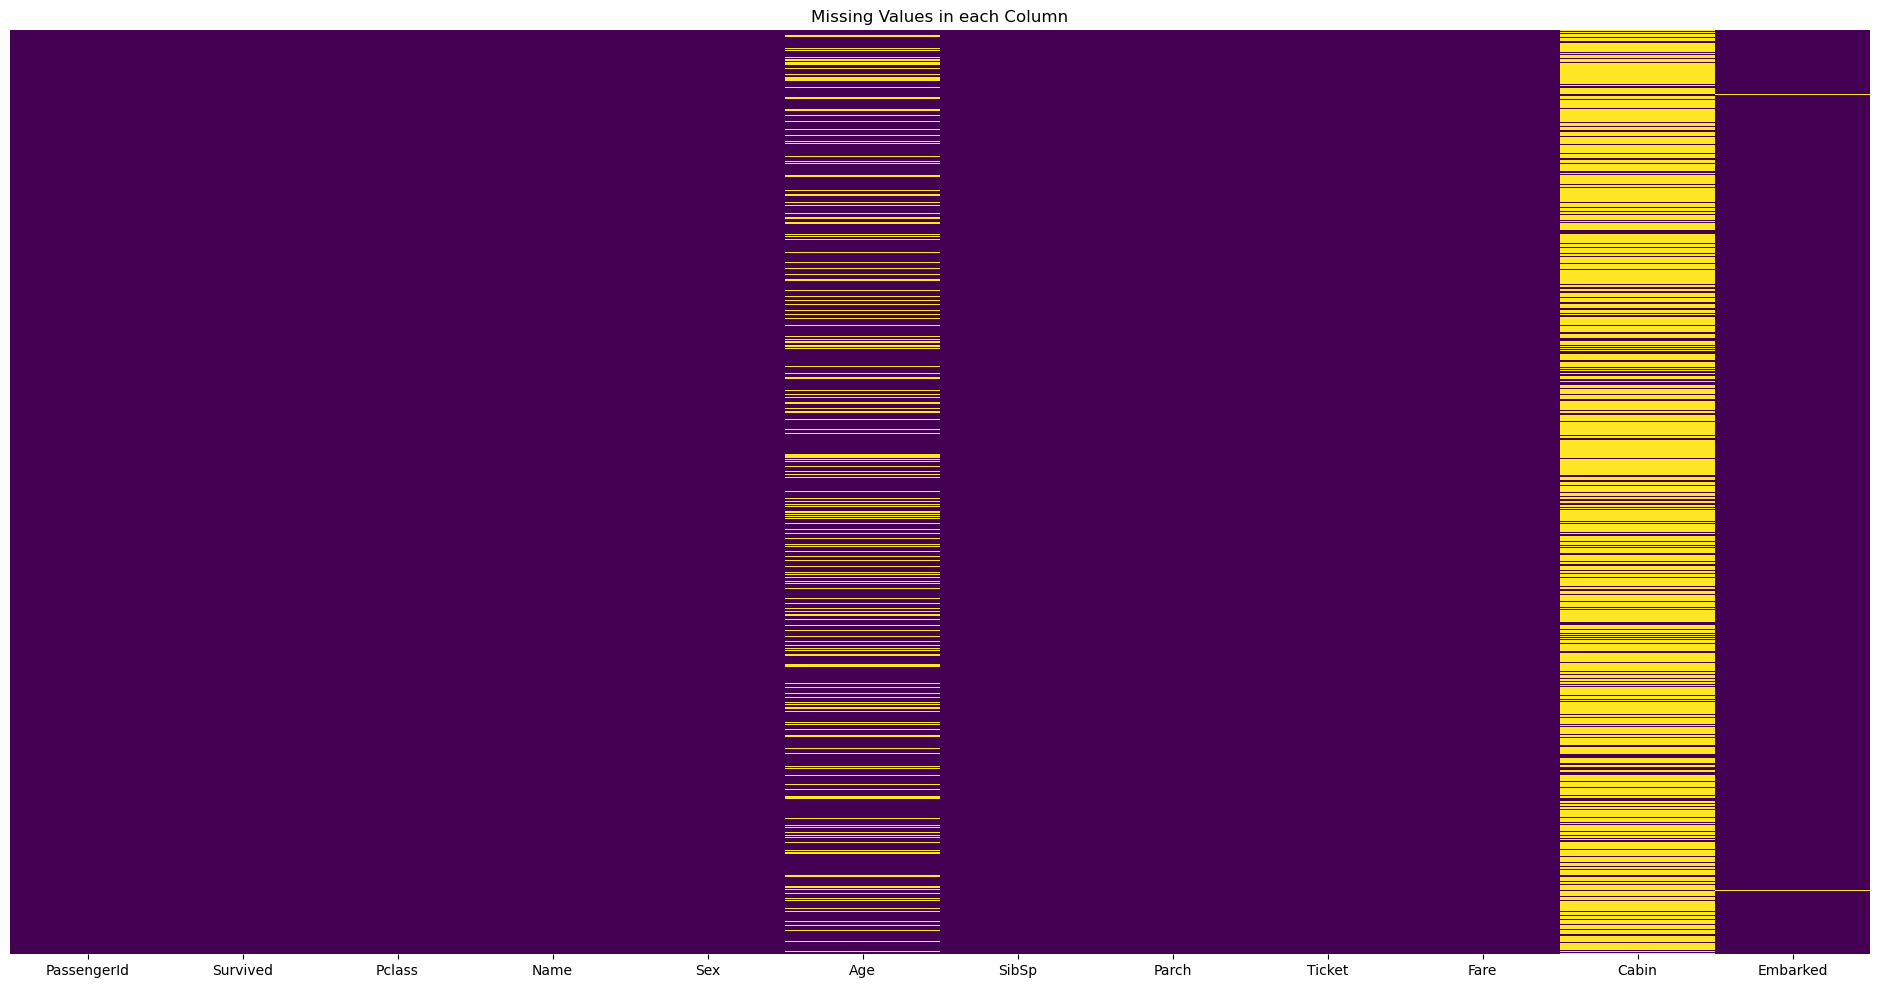

In [57]:
plt.figure(figsize=(24,12)) # Sets the size of the plot to be wide and tall, making it easy to see even large DataFrames.
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis') # healps easily see which parts of your data have missing values by plotting them visually.
plt.title('Missing Values in each Column')

Text(0.5, 1.0, 'Percentage of Missing Values in each Column')

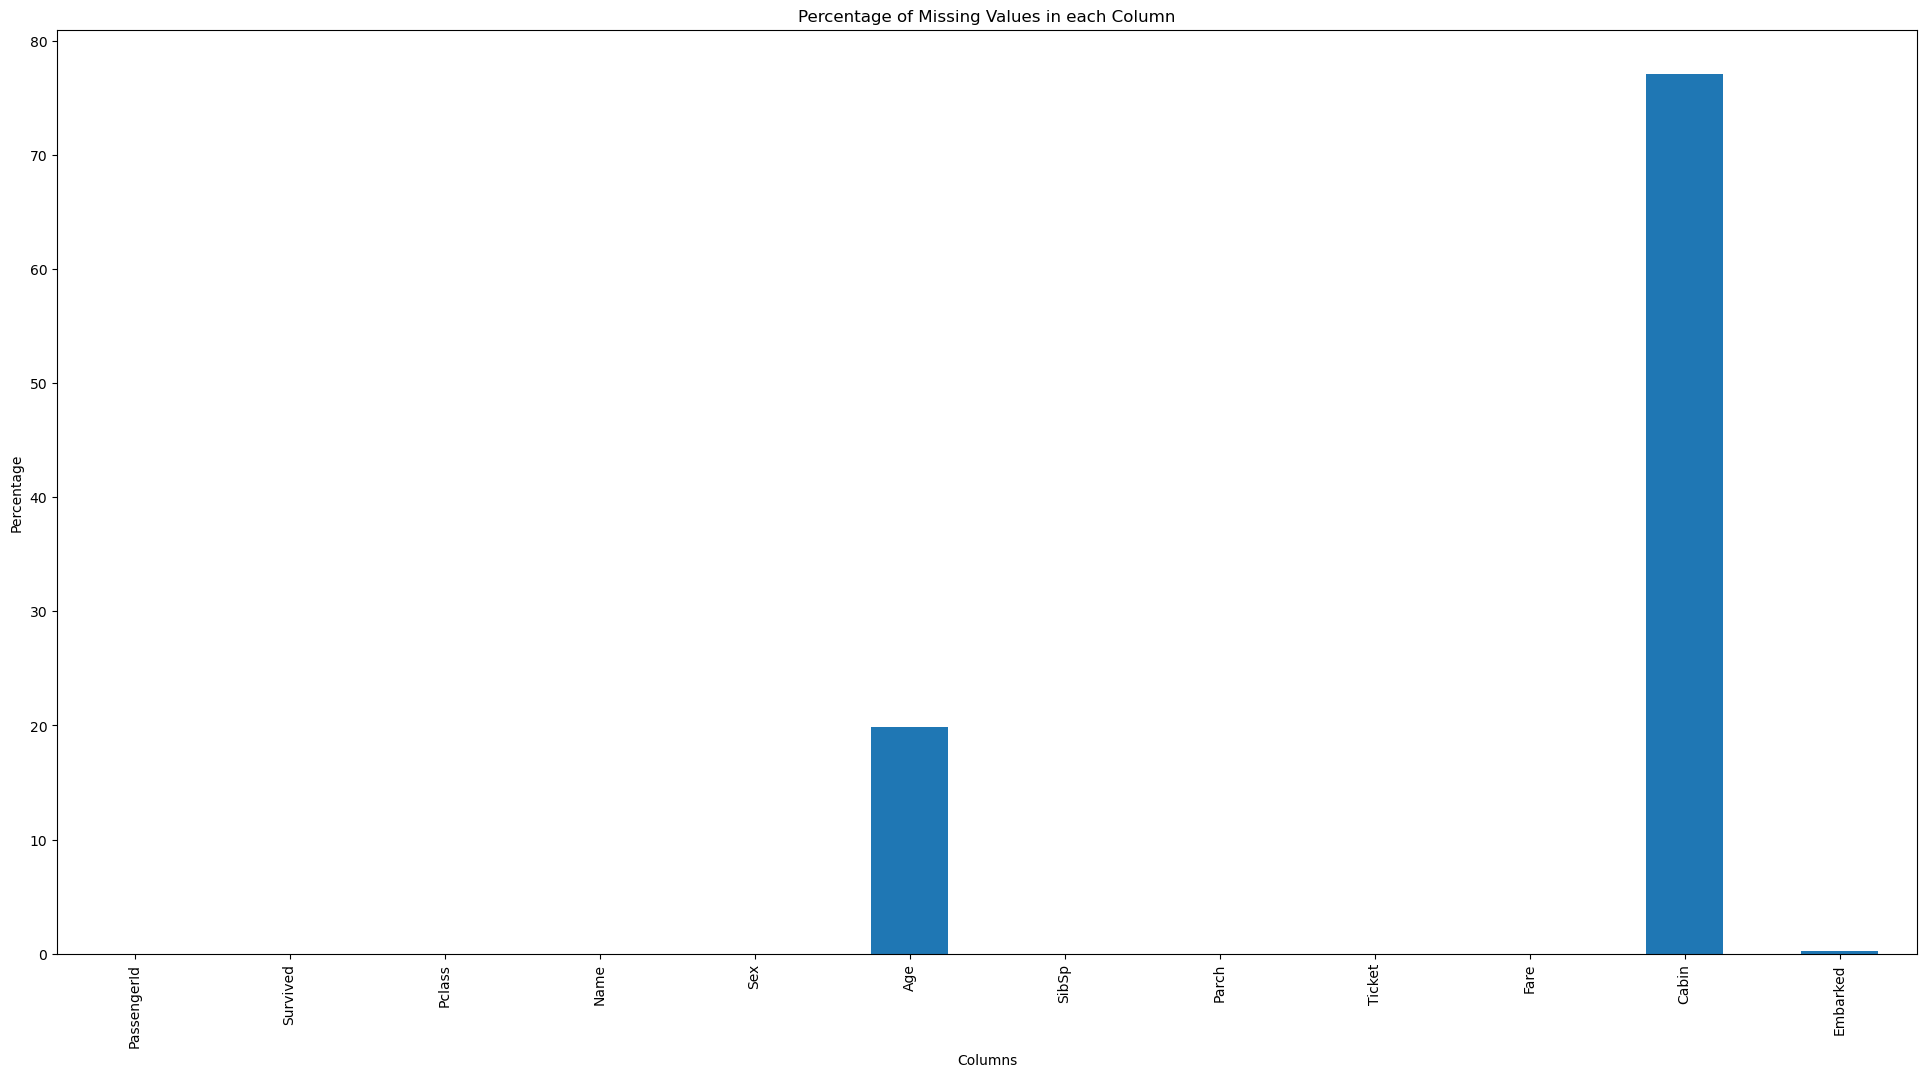

In [58]:

plt.figure(figsize=(24, 12))
# plot the missing values by their percentage in each column on a bar chart
missing_percentage = df.isnull().sum()/len(df)*100 
missing_percentage.plot(kind='bar')
# adding labels to the bar chart
plt.xlabel('Columns')
plt.ylabel('Percentage')
plt.title('Percentage of Missing Values in each Column')

In [59]:
df = df.drop('Cabin', axis=1) # Drop the 'Cabin' column since there are too many missing values and it has little useful data.
df = df.dropna(subset=['Age', 'Embarked']) # Drop rows where 'Age' or 'Embarked' is missing
df = df.reset_index(drop=True) # Reset the index after dropping rows 

In [60]:
df.isnull().sum().sort_values # checking if all the missing values has been removed

<bound method Series.sort_values of PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64>

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 712 entries, 0 to 711
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  712 non-null    int64  
 1   Survived     712 non-null    int64  
 2   Pclass       712 non-null    int64  
 3   Name         712 non-null    object 
 4   Sex          712 non-null    object 
 5   Age          712 non-null    float64
 6   SibSp        712 non-null    int64  
 7   Parch        712 non-null    int64  
 8   Ticket       712 non-null    object 
 9   Fare         712 non-null    float64
 10  Embarked     712 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 61.3+ KB


All the missing values have been removed

In [67]:
df.duplicated().any() # checking for any duplicated data 

np.False_

There is no duplicated  data

### Generate summary statistics and group-based insights (e.g., survival by gender/class)

In [71]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,712.000000,712.000000,712.000000,712.000000,712.000000,712.000000,712.000000
mean,448.589888,0.404494,2.240169,29.642093,0.514045,0.432584,34.567251
std,258.683191,0.491139,0.836854,14.492933,0.930692,0.854181,52.938648
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,222.750000,0.000000,1.000000,20.000000,0.000000,0.000000,8.050000
50%,445.000000,0.000000,2.000000,28.000000,0.000000,0.000000,15.645850
75%,677.250000,1.000000,3.000000,38.000000,1.000000,1.000000,33.000000
max,891.000000,1.000000,3.000000,80.000000,5.000000,6.000000,512.329200


In [79]:
print(df.groupby('Sex')['Survived'].mean().round(2)) # Average survival by gender in decimal places

Sex
female    0.75
male      0.21
Name: Survived, dtype: float64


In [80]:
print(df.groupby('Pclass')['Survived'].mean().round(2)) # Average survival by class in 2 decimal place

Pclass
1    0.65
2    0.48
3    0.24
Name: Survived, dtype: float64


In [81]:
#print(df.groupby('Age')['Survived'].mean().round(2))

In [82]:
print(df.groupby(['Pclass', 'Sex'])['Survived'].mean().round(2)) # Average surval by class and sex in 2 decimal places

Pclass  Sex   
1       female    0.96
        male      0.40
2       female    0.92
        male      0.15
3       female    0.46
        male      0.15
Name: Survived, dtype: float64


The statistical results show that,
- 75% of the survivors were Female while 21% were male
- The majority of the people who survived were in the first class, with a survival rate of 65%
- 96% of the females in the first class survive while just 40% of the males in the same class survived
- Generally, the percentage of survival decreases as you move from the first class to the third class

### Visualize key patterns and correlations 

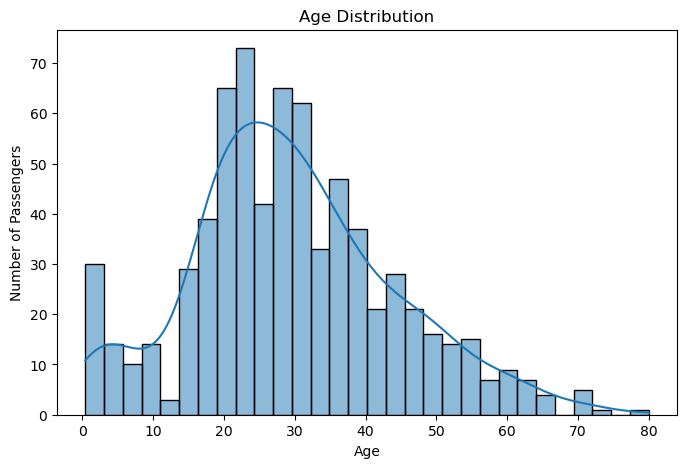

In [84]:
# The histogram of age of the passengers
plt.figure(figsize=(8,5))
sns.histplot(df['Age'], bins=30, kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')
plt.show()

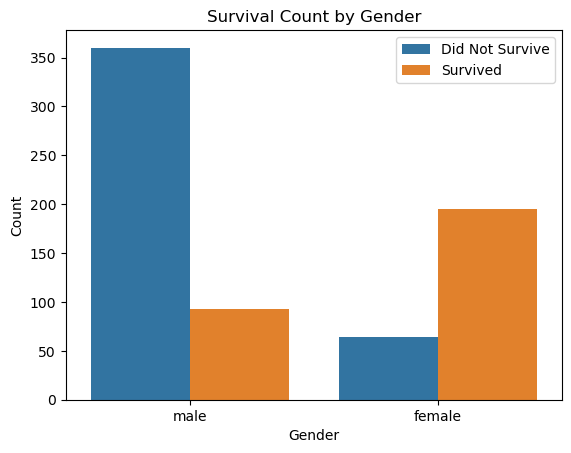

In [85]:
# Survival Rate by Gender in a bar chart
sns.countplot(x='Sex', hue='Survived', data=df)
plt.title('Survival Count by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(['Did Not Survive', 'Survived'])
plt.show()

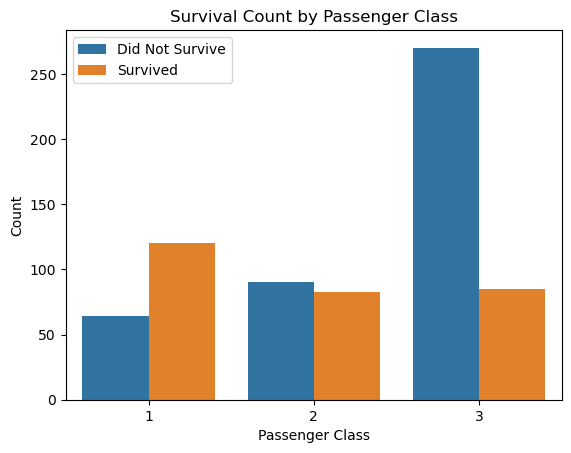

In [87]:
#Survival Rate by Class in a bar chart
sns.countplot(x='Pclass', hue='Survived', data=df)
plt.title('Survival Count by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Count')
plt.legend(['Did Not Survive', 'Survived'])
plt.show()

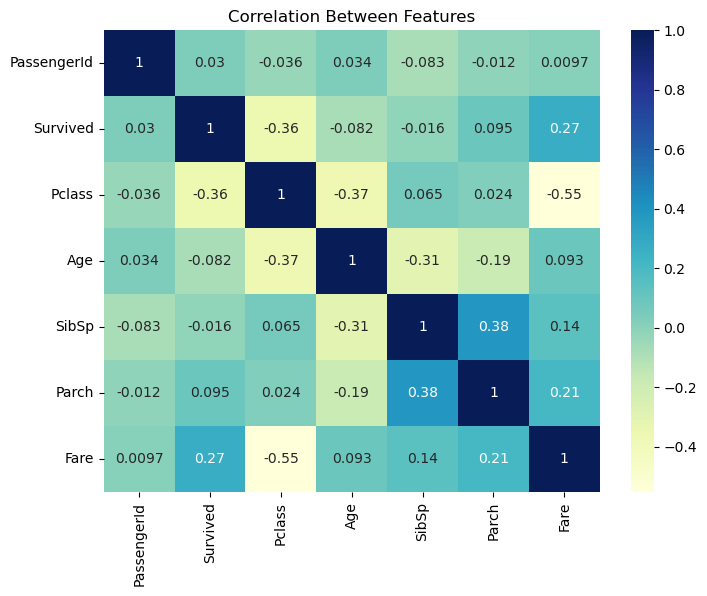

In [93]:
# Correlation Heatmap focusing only the numeric columns
numeric_df = df.select_dtypes(include=['number'])
plt.figure(figsize=(8,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='YlGnBu')
plt.title('Correlation Between Features')
plt.show()